In [1]:
import math
import random
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

print("Biblioteki zostały zaimportowane poprawnie.")

Biblioteki zostały zaimportowane poprawnie.


In [2]:

def generate_poisson(lam, n):
    if lam <= 0:
        raise ValueError("Parametr lambda musi być większy od zera.")
    if n <= 0:
        raise ValueError("Liczba generowanych wartości musi być większa od zera.")

    results = []

    for _ in range(n):
        u = random.random()

        x = 0
        q = math.exp(-lam)
        p = q
        s = q

        while u > s:
            x += 1
            p = p * lam / x
            s += p

        results.append(x)

    return results


poisson_values = generate_poisson(4, 1000)

print("Pierwsze 20 wygenerowanych wartości:")
print(poisson_values[:20])

print("Średnia z próby:", sum(poisson_values) / len(poisson_values))


Pierwsze 20 wygenerowanych wartości:
[8, 1, 2, 5, 6, 6, 0, 5, 6, 3, 6, 6, 4, 0, 4, 7, 2, 4, 6, 3]
Średnia z próby: 3.886


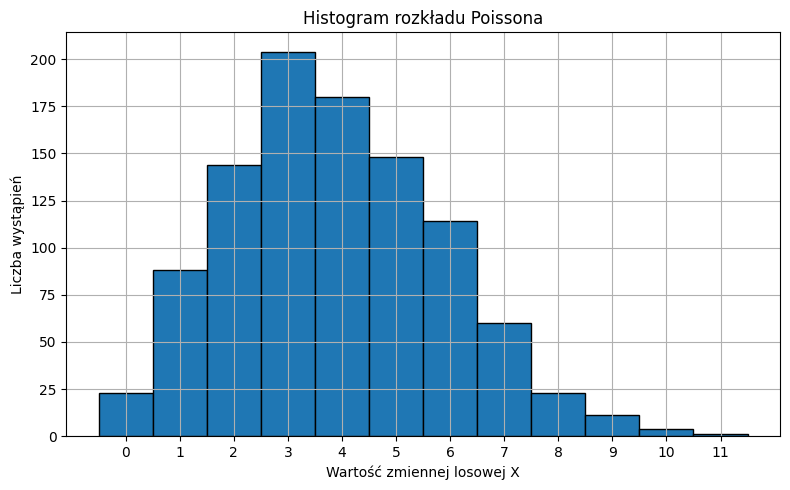

In [3]:

plt.figure()
plt.hist(
    poisson_values,
    bins=range(min(poisson_values), max(poisson_values) + 2),
    edgecolor="black",
    align="left"
)

plt.title("Histogram rozkładu Poissona")
plt.xlabel("Wartość zmiennej losowej X")
plt.ylabel("Liczba wystąpień")
plt.xticks(range(min(poisson_values), max(poisson_values) + 1))
plt.tight_layout()
plt.show()


In [4]:

def generate_normal(mu, sigma, n):
    if sigma <= 0:
        raise ValueError("Odchylenie standardowe sigma musi być większe od zera.")
    if n <= 0:
        raise ValueError("Liczba generowanych wartości musi być większa od zera.")

    results = []

    while len(results) < n:
        u1 = random.random()
        u2 = random.random()

        if u1 == 0:
            continue

        z1 = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
        z2 = math.sqrt(-2 * math.log(u1)) * math.sin(2 * math.pi * u2)

        results.append(mu + sigma * z1)

        if len(results) < n:
            results.append(mu + sigma * z2)

    return results


normal_values = generate_normal(0, 1, 1000)

print("Pierwsze 20 wygenerowanych wartości:")
print(normal_values[:20])

print("Średnia z próby:", sum(normal_values) / len(normal_values))



Pierwsze 20 wygenerowanych wartości:
[-0.44192247132391066, 1.6016426582380276, -0.8786862916852296, 1.134078913179725, -0.7765587354063203, -0.03439639596335855, -0.8694090091141438, 3.3616808756806904, -0.7577221595882384, -0.9718541299021565, -0.569697444937863, 0.34695769081462496, -0.6256107890060394, -1.2166064921397544, -1.5638932661721974, -1.369848180357997, -0.16598017543624843, 1.0112255399063896, 0.3171650277548831, 0.025717379599851226]
Średnia z próby: -0.005242436277666696


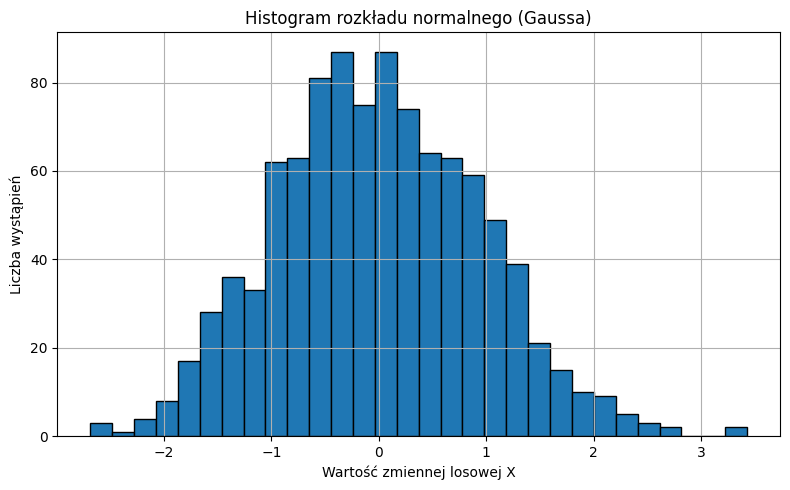

In [5]:

plt.figure()

plt.hist(
    normal_values,
    bins=30,
    edgecolor="black"
)

plt.title("Histogram rozkładu normalnego (Gaussa)")
plt.xlabel("Wartość zmiennej losowej X")
plt.ylabel("Liczba wystąpień")
plt.tight_layout()
plt.show()


In [6]:

def set_seed(seed=None):
    if seed is None:
        random.seed(None)
        print("Generowanie bez ustalonego ziarna.")
    else:
        random.seed(seed)
        print(f"Ustawiono ziarno: {seed}")


set_seed(42)
test_1 = generate_poisson(4, 10)

set_seed(42)
test_2 = generate_poisson(4, 10)

print("Wyniki identyczne:", test_1 == test_2)
print("Wygenerowane wartości:", test_1)


Ustawiono ziarno: 42
Ustawiono ziarno: 42
Wyniki identyczne: True
Wygenerowane wartości: [5, 1, 3, 2, 5, 5, 7, 1, 3, 1]


Generation mode: SEED = 42

--- Poisson Distribution ---
Lambda: 4.0
Number of values: 1000
Sample mean: 4.1110
Theoretical mean: 4.0

--- Normal Distribution ---
Mu: 0.0
Sigma: 1.0
Number of values: 1000
Sample mean: -0.0318
Sample standard deviation: 0.9885


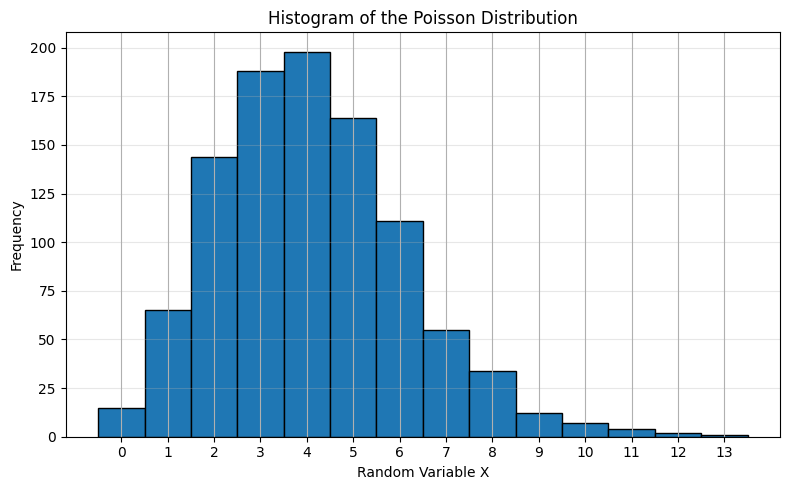

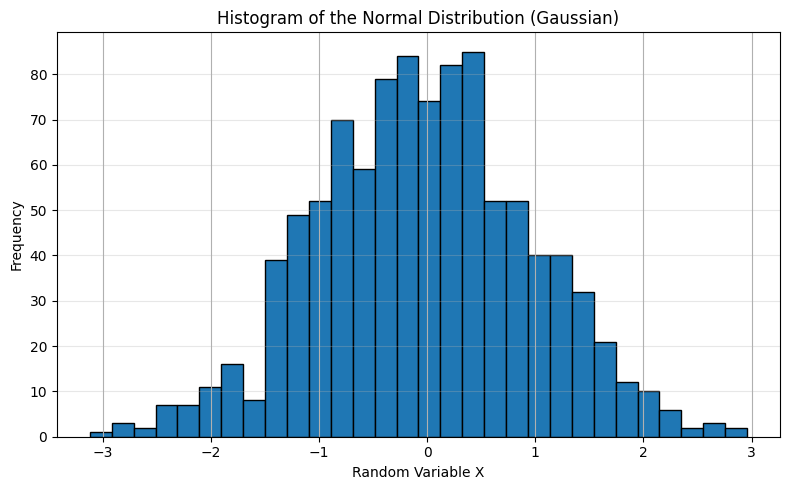

In [7]:

import math
import random
import matplotlib.pyplot as plt


N = 1000
LAMBDA = 4.0
MU = 0.0
SIGMA = 1.0
SEED = 42


def generate_poisson(lam, n, rng):
    if lam <= 0:
        raise ValueError("Lambda must be greater than zero.")
    if n <= 0:
        raise ValueError("The number of values must be greater than zero.")

    results = []
    q = math.exp(-lam)

    for _ in range(n):
        u = rng.random()
        x = 0
        p = q
        s = q

        while u > s:
            x += 1
            p = p * lam / x
            s += p

        results.append(x)

    return results


def generate_normal(mu, sigma, n, rng):
    if sigma <= 0:
        raise ValueError("Sigma must be greater than zero.")
    if n <= 0:
        raise ValueError("The number of values must be greater than zero.")

    results = []

    while len(results) < n:
        u1 = rng.random()
        u2 = rng.random()

        if u1 == 0:
            continue

        z1 = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
        z2 = math.sqrt(-2 * math.log(u1)) * math.sin(2 * math.pi * u2)

        results.append(mu + sigma * z1)

        if len(results) < n:
            results.append(mu + sigma * z2)

    return results


rng = random.Random(SEED)

if SEED is None:
    print("Generation mode: without a fixed seed")
else:
    print(f"Generation mode: SEED = {SEED}")

poisson_values = generate_poisson(LAMBDA, N, rng)
normal_values = generate_normal(MU, SIGMA, N, rng)

poisson_mean = sum(poisson_values) / N
normal_mean = sum(normal_values) / N

normal_std = math.sqrt(
    sum((x - normal_mean) ** 2 for x in normal_values) / (N - 1)
)

print("\n--- Poisson Distribution ---")
print(f"Lambda: {LAMBDA}")
print(f"Number of values: {N}")
print(f"Sample mean: {poisson_mean:.4f}")
print(f"Theoretical mean: {LAMBDA}")

print("\n--- Normal Distribution ---")
print(f"Mu: {MU}")
print(f"Sigma: {SIGMA}")
print(f"Number of values: {N}")
print(f"Sample mean: {normal_mean:.4f}")
print(f"Sample standard deviation: {normal_std:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(
    poisson_values,
    bins=[x - 0.5 for x in range(max(poisson_values) + 2)],
    edgecolor="black"
)
plt.title("Histogram of the Poisson Distribution")
plt.xlabel("Random Variable X")
plt.ylabel("Frequency")
plt.xticks(range(max(poisson_values) + 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(normal_values, bins=30, edgecolor="black")
plt.title("Histogram of the Normal Distribution (Gaussian)")
plt.xlabel("Random Variable X")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Generation mode: without a fixed seed

--- Poisson Distribution ---
Lambda: 4.0
Number of values: 1000
Sample mean: 3.9190
Theoretical mean: 4.0

--- Normal Distribution ---
Mu: 0.0
Sigma: 1.0
Number of values: 1000
Sample mean: 0.0410
Sample standard deviation: 0.9793


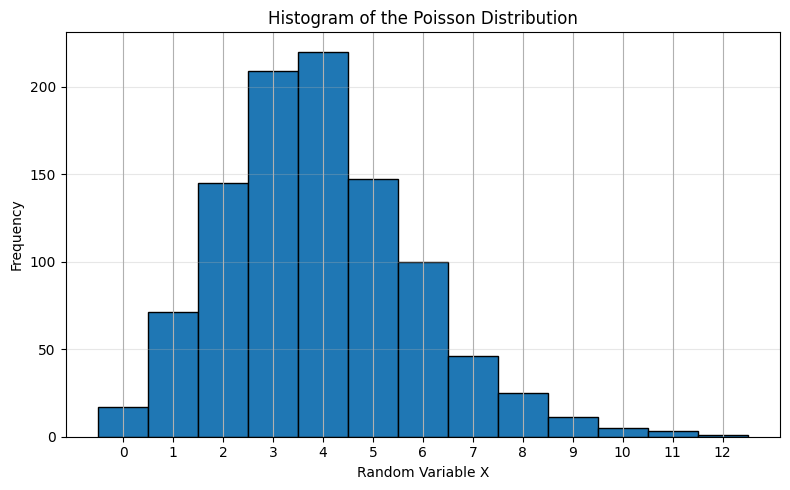

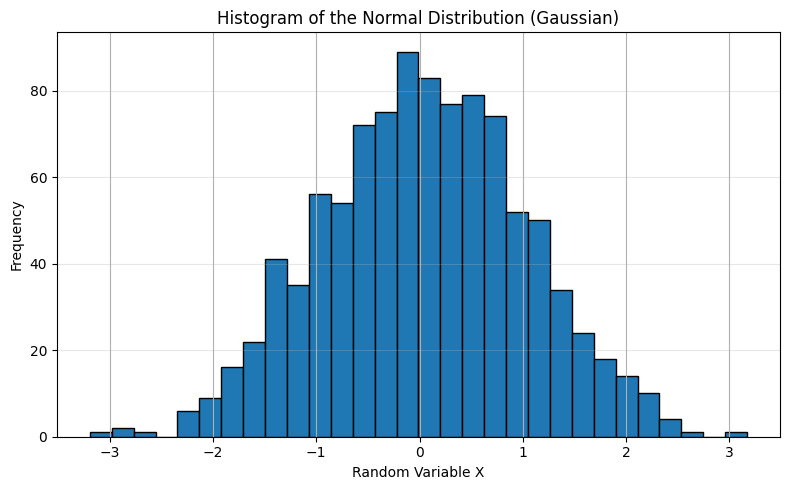

In [8]:

import math
import random
import matplotlib.pyplot as plt


N = 1000
LAMBDA = 4.0
MU = 0.0
SIGMA = 1.0
SEED = None


def generate_poisson(lam, n, rng):
    if lam <= 0:
        raise ValueError("Lambda must be greater than zero.")
    if n <= 0:
        raise ValueError("The number of values must be greater than zero.")

    results = []
    q = math.exp(-lam)

    for _ in range(n):
        u = rng.random()
        x = 0
        p = q
        s = q

        while u > s:
            x += 1
            p = p * lam / x
            s += p

        results.append(x)

    return results


def generate_normal(mu, sigma, n, rng):
    if sigma <= 0:
        raise ValueError("Sigma must be greater than zero.")
    if n <= 0:
        raise ValueError("The number of values must be greater than zero.")

    results = []

    while len(results) < n:
        u1 = rng.random()
        u2 = rng.random()

        if u1 == 0:
            continue

        z1 = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
        z2 = math.sqrt(-2 * math.log(u1)) * math.sin(2 * math.pi * u2)

        results.append(mu + sigma * z1)

        if len(results) < n:
            results.append(mu + sigma * z2)

    return results


rng = random.Random(SEED)

if SEED is None:
    print("Generation mode: without a fixed seed")
else:
    print(f"Generation mode: SEED = {SEED}")

poisson_values = generate_poisson(LAMBDA, N, rng)
normal_values = generate_normal(MU, SIGMA, N, rng)

poisson_mean = sum(poisson_values) / N
normal_mean = sum(normal_values) / N

normal_std = math.sqrt(
    sum((x - normal_mean) ** 2 for x in normal_values) / (N - 1)
)

print("\n--- Poisson Distribution ---")
print(f"Lambda: {LAMBDA}")
print(f"Number of values: {N}")
print(f"Sample mean: {poisson_mean:.4f}")
print(f"Theoretical mean: {LAMBDA}")

print("\n--- Normal Distribution ---")
print(f"Mu: {MU}")
print(f"Sigma: {SIGMA}")
print(f"Number of values: {N}")
print(f"Sample mean: {normal_mean:.4f}")
print(f"Sample standard deviation: {normal_std:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(
    poisson_values,
    bins=[x - 0.5 for x in range(max(poisson_values) + 2)],
    edgecolor="black"
)
plt.title("Histogram of the Poisson Distribution")
plt.xlabel("Random Variable X")
plt.ylabel("Frequency")
plt.xticks(range(max(poisson_values) + 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(normal_values, bins=30, edgecolor="black")
plt.title("Histogram of the Normal Distribution (Gaussian)")
plt.xlabel("Random Variable X")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
